In [1]:
!nvidia-smi

Wed Oct  7 17:46:25 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   50C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
!unzip -q "/content/drive/MyDrive/archive.zip" -d /content/fer2013
!ls /content/fer2013

test  train


In [4]:
import os
for split in ["train", "test"]:
    print(split)
    for cls in sorted(os.listdir(f"/content/fer2013/{split}")):
        n = len(os.listdir(f"/content/fer2013/{split}/{cls}"))
        print(f"  {cls}: {n}")

train
  angry: 3995
  disgust: 436
  fear: 4097
  happy: 7215
  neutral: 4965
  sad: 4830
  surprise: 3171
test
  angry: 958
  disgust: 111
  fear: 1024
  happy: 1774
  neutral: 1233
  sad: 1247
  surprise: 831


In [5]:
!git clone -q https://github.com/microsoft/FERPlus /content/FERPlus
!ls /content/FERPlus

data  fer2013new.csv  FER+vsFER.png  LICENSE.md  README.md  SECURITY.md  src


In [6]:
!unzip -q "/content/drive/MyDrive/fer2013csv.zip" -d /content/fer_csv
!ls /content/fer_csv

fer2013.csv


In [7]:
import pandas as pd
old = pd.read_csv("/content/fer_csv/fer2013.csv")
new = pd.read_csv("/content/FERPlus/fer2013new.csv")
print(len(old), len(new))
print(new.head())

35887 35887
      Usage      Image name  neutral  happiness  surprise  sadness  anger  \
0  Training  fer0000000.png        4          0         0        1      3   
1  Training  fer0000001.png        6          0         1        1      0   
2  Training  fer0000002.png        5          0         0        3      1   
3  Training  fer0000003.png        4          0         0        4      1   
4  Training  fer0000004.png        9          0         0        1      0   

   disgust  fear  contempt  unknown  NF  
0        2     0         0        0   0  
1        0     0         0        2   0  
2        0     0         0        1   0  
3        0     0         0        1   0  
4        0     0         0        0   0  


In [8]:
import numpy as np
emotions = ["neutral","happiness","surprise","sadness","anger","disgust","fear","contempt"]
votes = new[emotions].values
top = votes.max(axis=1)
is_tie = (votes == top[:, None]).sum(axis=1) > 1
keep = (top > new["unknown"]) & (top > new["NF"]) & ~is_tie & new["Image name"].notna()
labels = votes.argmax(axis=1)
print("kept", keep.sum(), "of", len(new))

kept 33712 of 35887


In [9]:
X = np.stack([np.array(p.split(), dtype=np.uint8).reshape(48, 48) for p in old["pixels"]])
X, y, usage = X[keep.values], labels[keep.values], new["Usage"][keep].values.astype(str)
print(X.shape, y.shape)

(33712, 48, 48) (33712,)


In [10]:
for split in ["Training", "PublicTest", "PrivateTest"]:
    counts = np.bincount(y[usage == split], minlength=8)
    print(split, (usage == split).sum())
    print("  ", dict(zip(emotions, counts)))

Training 26940
   {'neutral': np.int64(9365), 'happiness': np.int64(7410), 'surprise': np.int64(3378), 'sadness': np.int64(3403), 'anger': np.int64(2399), 'disgust': np.int64(175), 'fear': np.int64(648), 'contempt': np.int64(162)}
PublicTest 3396
   {'neutral': np.int64(1242), 'happiness': np.int64(880), 'surprise': np.int64(441), 'sadness': np.int64(395), 'anger': np.int64(310), 'disgust': np.int64(31), 'fear': np.int64(73), 'contempt': np.int64(24)}
PrivateTest 3376
   {'neutral': np.int64(1166), 'happiness': np.int64(909), 'surprise': np.int64(421), 'sadness': np.int64(424), 'anger': np.int64(316), 'disgust': np.int64(22), 'fear': np.int64(92), 'contempt': np.int64(26)}


In [11]:
np.savez_compressed("/content/drive/MyDrive/ferplus_clean.npz", X=X, y=y, usage=usage)

In [12]:
import tensorflow as tf
from sklearn.utils.class_weight import compute_class_weight
tr, va, te = usage == "Training", usage == "PublicTest", usage == "PrivateTest"
Xtr, ytr, Xva, yva, Xte, yte = X[tr], y[tr], X[va], y[va], X[te], y[te]
w = compute_class_weight("balanced", classes=np.arange(8), y=ytr)
class_weight = dict(enumerate(np.sqrt(w)))
print(class_weight)

{0: np.float64(0.5996528627404739), 1: np.float64(0.6741316201570332), 2: np.float64(0.9984446163233136), 3: np.float64(0.9947703394303645), 4: np.float64(1.1847826294794748), 5: np.float64(4.386668114053894), 6: np.float64(2.279640160038259), 7: np.float64(4.559280320076518)}


In [13]:
def prep(x, label):
    return tf.cast(x[..., None], tf.float32) / 255.0, label
def make_ds(Xs, ys, train):
    ds = tf.data.Dataset.from_tensor_slices((Xs, ys)).map(prep)
    if train: ds = ds.shuffle(10000)
    return ds.batch(64).prefetch(tf.data.AUTOTUNE)
train_ds, val_ds, test_ds = make_ds(Xtr, ytr, True), make_ds(Xva, yva, False), make_ds(Xte, yte, False)

In [14]:
L = tf.keras.layers
def block(x, filters, n):
    for _ in range(n):
        x = L.Conv2D(filters, 3, padding="same", use_bias=False)(x)
        x = L.ReLU()(L.BatchNormalization()(x))
    return L.Dropout(0.25)(L.MaxPooling2D()(x))
aug = tf.keras.Sequential([L.RandomFlip("horizontal"), L.RandomRotation(0.05),
                           L.RandomZoom(0.1), L.RandomTranslation(0.1, 0.1)])

In [15]:
inputs = tf.keras.Input((48, 48, 1))
x = aug(inputs)
for f, n in [(64, 2), (128, 2), (256, 3), (256, 3)]:
    x = block(x, f, n)
x = L.Flatten()(x)
x = L.Dropout(0.5)(L.Dense(1024, activation="relu")(x))
x = L.Dropout(0.5)(L.Dense(1024, activation="relu")(x))
outputs = L.Dense(8, activation="softmax")(x)
model = tf.keras.Model(inputs, outputs)
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 48, 48, 64)     │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 48, 48, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 48, 48, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 48, 48, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 48, 48, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 48, 48, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 24, 24, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 24, 24, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 24, 24, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 24, 24, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 24, 24, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 24, 24, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 12, 12, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 12, 12, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_4 (ReLU)                  │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 12, 12, 256)    │       589,824 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 6,928,456 (26.43 MB)

 Trainable params: 6,924,616 (26.42 MB)

 Non-trainable params: 3,840 (15.00 KB)

In [19]:
cbs = [tf.keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=10, restore_best_weights=True),
       tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=3),
       tf.keras.callbacks.ModelCheckpoint("/content/drive/MyDrive/emotion_cnn.keras", monitor="val_accuracy", save_best_only=True)]
history = model.fit(train_ds, validation_data=val_ds, epochs=80, class_weight=class_weight, callbacks=cbs)

Epoch 1/80
421/421 ━━━━━━━━━━━━━━━━━━━━ 41s 80ms/step - accuracy: 0.2903 - loss: 1.7619 - val_accuracy: 0.3660 - val_loss: 1.8308 - learning_rate: 3.0000e-04
Epoch 2/80
421/421 ━━━━━━━━━━━━━━━━━━━━ 35s 82ms/step - accuracy: 0.4130 - loss: 1.5448 - val_accuracy: 0.5268 - val_loss: 1.5197 - learning_rate: 3.0000e-04
Epoch 3/80
421/421 ━━━━━━━━━━━━━━━━━━━━ 35s 81ms/step - accuracy: 0.5290 - loss: 1.3209 - val_accuracy: 0.4193 - val_loss: 1.5589 - learning_rate: 3.0000e-04
Epoch 4/80
421/421 ━━━━━━━━━━━━━━━━━━━━ 34s 81ms/step - accuracy: 0.5870 - loss: 1.1699 - val_accuracy: 0.6614 - val_loss: 1.0191 - learning_rate: 3.0000e-04
Epoch 5/80
421/421 ━━━━━━━━━━━━━━━━━━━━ 34s 80ms/step - accuracy: 0.6211 - loss: 1.0614 - val_accuracy: 0.5191 - val_loss: 1.3451 - learning_rate: 3.0000e-04
Epoch 6/80
421/421 ━━━━━━━━━━━━━━━━━━━━ 35s 82ms/step - accuracy: 0.6619 - loss: 0.9629 - val_accuracy: 0.6028 - val_loss: 1.1451 - learning_rate: 3.0000e-04
Epoch 7/80
421/421 ━━━━━━━━━━━━━━━━━━━━ 34s 80ms/ste

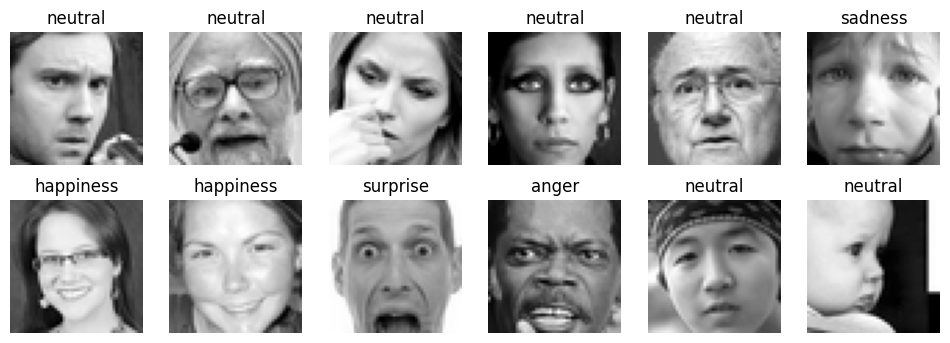

In [17]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(2, 6, figsize=(12, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(Xtr[i], cmap="gray"); ax.set_title(emotions[ytr[i]]); ax.axis("off")
plt.show()

In [18]:
inputs = tf.keras.Input((48, 48, 1))
x = aug(inputs)
for f, n in [(64, 2), (128, 2), (256, 3), (256, 3)]:
    x = block(x, f, n)
x = L.GlobalAveragePooling2D()(x)
x = L.Dense(256, use_bias=False)(x)
x = L.Dropout(0.4)(L.ReLU()(L.BatchNormalization()(x)))
outputs = L.Dense(8, activation="softmax")(x)
model = tf.keras.Model(inputs, outputs)
model.compile(optimizer=tf.keras.optimizers.Adam(3e-4), loss="sparse_categorical_crossentropy", metrics=["accuracy"])

In [20]:
model.evaluate(test_ds)

53/53 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step - accuracy: 0.7823 - loss: 0.6132


[0.6132317185401917, 0.7822867035865784]

53/53 ━━━━━━━━━━━━━━━━━━━━ 3s 41ms/step
              precision    recall  f1-score   support

     neutral      0.792     0.851     0.821      1166
   happiness      0.910     0.880     0.895       909
    surprise      0.842     0.810     0.826       421
     sadness      0.670     0.432     0.525       424
       anger      0.617     0.820     0.704       316
     disgust      0.294     0.227     0.256        22
        fear      0.520     0.576     0.546        92
    contempt      0.286     0.308     0.296        26

    accuracy                          0.782      3376
   macro avg      0.616     0.613     0.609      3376
weighted avg      0.784     0.782     0.778      3376



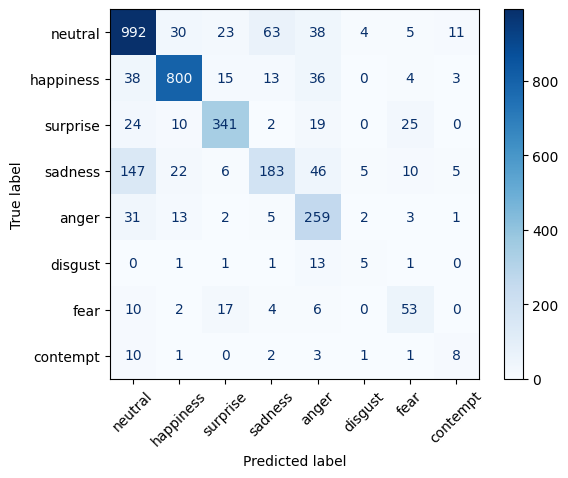

In [21]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
pred = model.predict(test_ds).argmax(axis=1)
print(classification_report(yte, pred, target_names=emotions, digits=3))
ConfusionMatrixDisplay(confusion_matrix(yte, pred), display_labels=emotions).plot(xticks_rotation=45, cmap="Blues")
plt.show()

In [22]:
soft = votes[keep.values].astype("float32")
soft = soft / soft.sum(axis=1, keepdims=True)
Ytr, Yva = soft[tr], soft[va]
np.savez_compressed("/content/drive/MyDrive/ferplus_soft.npz", soft=soft)
print(Ytr.shape)
print(dict(zip(emotions, Ytr[0].round(2))), "→ old label:", emotions[ytr[0]])

(26940, 8)
{'neutral': np.float32(0.4), 'happiness': np.float32(0.0), 'surprise': np.float32(0.0), 'sadness': np.float32(0.1), 'anger': np.float32(0.3), 'disgust': np.float32(0.2), 'fear': np.float32(0.0), 'contempt': np.float32(0.0)} → old label: neutral


In [23]:
train_ds2 = make_ds(Xtr, Ytr, True)
val_ds2 = make_ds(Xva, Yva, False)

In [24]:
def block2(x, filters, n, drop=0.2):
    for _ in range(n):
        x = L.Conv2D(filters, 3, padding="same", use_bias=False)(x)
        x = L.ReLU()(L.BatchNormalization()(x))
    return L.Dropout(drop)(L.MaxPooling2D()(x))
inputs = tf.keras.Input((48, 48, 1))
x = aug(inputs)
for f, n in [(64, 2), (128, 2), (256, 3), (256, 3)]:
    x = block2(x, f, n)
x = L.GlobalAveragePooling2D()(x)
x = L.Dropout(0.3)(L.ReLU()(L.BatchNormalization()(L.Dense(512, use_bias=False)(x))))
outputs = L.Dense(8, activation="softmax")(x)
model2 = tf.keras.Model(inputs, outputs)

In [25]:
EPOCHS, steps = 60, len(train_ds2)
sched = tf.keras.optimizers.schedules.CosineDecay(1e-5, (EPOCHS - 3) * steps, warmup_target=5e-4, warmup_steps=3 * steps)
model2.compile(optimizer=tf.keras.optimizers.AdamW(sched, weight_decay=1e-4), loss="categorical_crossentropy", metrics=["accuracy"])
ckpt = tf.keras.callbacks.ModelCheckpoint("/content/drive/MyDrive/emotion_cnn_v2.keras", monitor="val_accuracy", save_best_only=True)
history2 = model2.fit(train_ds2, validation_data=val_ds2, epochs=EPOCHS, callbacks=[ckpt])

Epoch 1/60
421/421 ━━━━━━━━━━━━━━━━━━━━ 55s 86ms/step - accuracy: 0.2824 - loss: 2.0078 - val_accuracy: 0.3663 - val_loss: 1.9180
Epoch 2/60
421/421 ━━━━━━━━━━━━━━━━━━━━ 35s 83ms/step - accuracy: 0.4284 - loss: 1.6718 - val_accuracy: 0.4879 - val_loss: 1.6966
Epoch 3/60
421/421 ━━━━━━━━━━━━━━━━━━━━ 35s 83ms/step - accuracy: 0.5485 - loss: 1.4504 - val_accuracy: 0.4838 - val_loss: 1.6744
Epoch 4/60
421/421 ━━━━━━━━━━━━━━━━━━━━ 35s 83ms/step - accuracy: 0.6204 - loss: 1.2672 - val_accuracy: 0.5518 - val_loss: 1.5047
Epoch 5/60
421/421 ━━━━━━━━━━━━━━━━━━━━ 37s 86ms/step - accuracy: 0.6737 - loss: 1.1480 - val_accuracy: 0.7244 - val_loss: 1.0453
Epoch 6/60
421/421 ━━━━━━━━━━━━━━━━━━━━ 36s 84ms/step - accuracy: 0.7059 - loss: 1.0819 - val_accuracy: 0.6999 - val_loss: 1.0947
Epoch 7/60
421/421 ━━━━━━━━━━━━━━━━━━━━ 36s 84ms/step - accuracy: 0.7251 - loss: 1.0420 - val_accuracy: 0.7297 - val_loss: 1.0260
Epoch 8/60
421/421 ━━━━━━━━━━━━━━━━━━━━ 36s 84ms/step - accuracy: 0.7429 - loss: 1.0094 - 

In [26]:
best = tf.keras.models.load_model("/content/drive/MyDrive/emotion_cnn_v2.keras")
flip = lambda ds: ds.map(lambda x, l: (tf.image.flip_left_right(x), l))
for name, ds, ys in [("val", val_ds, yva), ("test", test_ds, yte)]:
    p = best.predict(ds, verbose=0)
    pf = best.predict(flip(ds), verbose=0)
    print(f"{name}: plain {(p.argmax(1) == ys).mean():.4f} | TTA {((p + pf).argmax(1) == ys).mean():.4f}")

val: plain 0.8628 | TTA 0.8648
test: plain 0.8501 | TTA 0.8519


              precision    recall  f1-score   support

     neutral      0.833     0.901     0.866      1166
   happiness      0.953     0.934     0.943       909
    surprise      0.827     0.884     0.854       421
     sadness      0.753     0.675     0.711       424
       anger      0.838     0.820     0.829       316
     disgust      0.500     0.318     0.389        22
        fear      0.723     0.511     0.599        92
    contempt      0.857     0.231     0.364        26

    accuracy                          0.852      3376
   macro avg      0.785     0.659     0.694      3376
weighted avg      0.850     0.852     0.848      3376



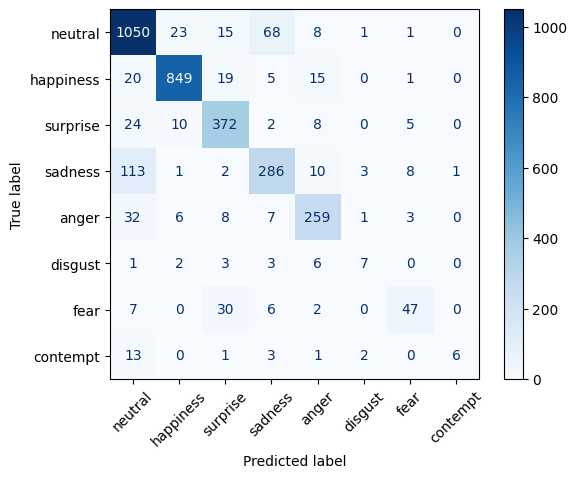

In [27]:
p = best.predict(test_ds, verbose=0) + best.predict(flip(test_ds), verbose=0)
pred2 = p.argmax(1)
print(classification_report(yte, pred2, target_names=emotions, digits=3))
ConfusionMatrixDisplay(confusion_matrix(yte, pred2), display_labels=emotions).plot(xticks_rotation=45, cmap="Blues")
plt.show()